# **PDAN8412: PART 2 - LOGISTIC REGRESSION**
### **ST10119837 - THULEDU TSHABALALA**
### Assignment Repository: https://github.com/VCONLINE/pdan8412-part-two-Thuledu

## **DATA SOURCE**
### Mohamedbakhet. 2023. Amazon Books Reviews, *Kaggle*. [Online]. Available at: https://www.kaggle.com/datasets/mohamedbakhet/amazon-books-reviews

<h2>Dataset Overview</h2>
<p>The Amazon Books Reviews dataset from Kaggle includes over 3 million review entries across two files: Books_rating.csv (reviews) and books_data.csv (book metadata). This scale supports robust modeling, with proxies like review counts indicating potential bestsellers.</p>

<p>Logistic regression classifies binary outcomes by modeling probabilities with a sigmoid, optimized via descent. A key component of binary classification is logistic regression, which models the probability of an event using a linear equation transformed by the sigmoid function: p = 1 / (1 + e^{-(β0 + β1x1 + ... + βnxn)}), where p is the probability, x are input features, and β coefficients are learnt through optimisation.  It is effective for datasets with linear separability in feature space because it minimises binary cross-entropy loss by optimising parameters, frequently by gradient descent(Cox, 1958). It has demonstrated effectiveness in review-based applications for tasks like as sentiment or popularity prediction, offering comprehensible insights through odds ratios obtained from coefficients(Hosmer, Lemeshow and Sturdivant, 2013).</p>

<h2>Dataset Justification and Relevance</h2>
The Amazon Books Reviews dataset, which is sourced from Kaggle, includes books_rating.csv (3,068,316 review entries) and books_data.csv (212,404 book entries) covering the years 1996–2014 (Mohamedbakhet, 2023).  Id, Title, User_id, profileName, review/helpfulness (e.g., "2/3"), review/score (1–5), review/time (Unix), review/summary, and review/text are among the columns in reviews.  Title, description, authors, image, previewLink, publisher, publishedDate, infoLink, categories, and ratingsCount are all included to book metadata.</p>
<p>This dataset fits logistic regression due to its binary-derivable target (e.g., bestseller = 1 if review_count > threshold), numerical features (e.g., avg_score, review_length), and vast size for stable estimates, reducing overfitting risks (Kleinbaum and Klein, 2010). Although not ideal, the review volume proxy for bestsellers is consistent with research demonstrating relationships between feedback and sales (Theobald, 2017).  Its size and structure validate the theoretical presumptions of independence and linearity in log-odds, in contrast to smaller or non-binary datasets.</p>
<p><b>Why Sigmoid in Logistic Regression</b></p>
<p>The sigmoid function transforms linear outputs into probabilities, ensuring predictions stay within [0,1]. This makes it suitable for binary decisions, like yes/no classifications, by modeling the log-odds ratio.</p>

<h2>Structured Analysis Plan</h2>

<p>Detailed Process Documentation</p>

<li>Data Integration: Load CSVs, merge, aggregate (group_by Title).</li>
<li>EDA: Summaries, plots for insights (e.g., top books by count identify bestsellers).</li>
<li>Wrangling: Feature creation (parse ratios, lengths), target derivation (threshold at 75th percentile for ~25% positives).</li>
<li>Modeling: Sigmoid, cost with reg, mini-batch descent for scale.</li>
<li>Tuning and Evaluation: Grid search tests alpha (0.001-0.1), iterations (200-800), lambda (0-1), minimizing test loss for balanced fit..</li>

<p>Model recommendation: Consider adding Random forests to capture non-linearities better (e.g., genre interactions), potentially lifting accuracy 8% (Breiman, 2001). SVMs for margins or boosting for imbalance, though less interpretable and Naive Bayes can also be considered to categorise reviews as either positive or negative in order to optimise the dataset's potential and facilitate rapid trend identification.</p>

<b>Please note that the Report will be in a separate document to this.</b>


### **Importing Libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, auc

np.random.seed(42)

### **Loading and Inspecting Data**

In [4]:
#!/bin/bash
! kaggle datasets download mohamedbakhet/amazon-books-reviews

Dataset URL: https://www.kaggle.com/datasets/mohamedbakhet/amazon-books-reviews
License(s): CC0-1.0
amazon-books-reviews.zip: Skipping, found more recently modified local copy (use --force to force download)


In [5]:
# This unzips the folder "amazon-books-reviews.zip" so that we can access the file within it.
!tar -xf amazon-books-reviews.zip

In [3]:
# Load data
reviews = pd.read_csv('Books_rating.csv')
books = pd.read_csv('books_data.csv')

In [ ]:
# Merge on Title
df_books_data = reviews.merge(books, on='Title', how='left')

print(df_books_data.shape) 
print(df_books_data.columns)

(3000000, 19)
Index(['Id', 'Title', 'Price', 'User_id', 'profileName', 'review/helpfulness',
       'review/score', 'review/time', 'review/summary', 'review/text',
       'description', 'authors', 'image', 'previewLink', 'publisher',
       'publishedDate', 'infoLink', 'categories', 'ratingsCount'],
      dtype='object')


In [ ]:
df_books_data.head()
# (IIE Emeris School of Computer Science, 2025)

,Id,Title,Price,User_id,profileName,review/helpfulness,review/score,review/time,review/summary,review/text,description,authors,image,previewLink,publisher,publishedDate,infoLink,categories,ratingsCount
0,1882931173,Its Only Art If Its Well Hung!,NaN,AVCGYZL8FQQTD,"Jim of Oz ""jim-of-oz""",7/7,4.0,940636800,Nice collection of Julie Strain images,This is only for Julie Strain fans. It's a col...,NaN,['Julie Strain'],http://books.google.com/books/content?id=DykPA...,http://books.google.nl/books?id=DykPAAAACAAJ&d...,NaN,1996,http://books.google.nl/books?id=DykPAAAACAAJ&d...,['Comics & Graphic Novels'],NaN
1,0826414346,Dr. Seuss: American Icon,NaN,A30TK6U7DNS82R,Kevin Killian,10/10,5.0,1095724800,Really Enjoyed It,I don't care much for Dr. Seuss but after read...,Philip Nel takes a fascinating look into the k...,['Philip Nel'],http://books.google.com/books/content?id=IjvHQ...,http://books.google.nl/books?id=IjvHQsCn_pgC&p...,A&C Black,2005-01-01,http://books.google.nl/books?id=IjvHQsCn_pgC&d...,['Biography & Autobiography'],NaN
2,0826414346,Dr. Seuss: American Icon,NaN,A3UH4UZ4RSVO82,John Granger,10/11,5.0,1078790400,Essential for every personal and Public Library,"If people become the books they read and if ""t...",Philip Nel takes a fascinating look into the k...,['Philip Nel'],http://books.google.com/books/content?id=IjvHQ...,http://books.google.nl/books?id=IjvHQsCn_pgC&p...,A&C Black,2005-01-01,http://books.google.nl/books?id=IjvHQsCn_pgC&d...,['Biography & Autobiography'],NaN
3,0826414346,Dr. Seuss: American Icon,NaN,A2MVUWT453QH61,"Roy E. Perry ""amateur philosopher""",7/7,4.0,1090713600,Phlip Nel gives silly Seuss a serious treatment,"Theodore Seuss Geisel (1904-1991), aka &quot;D...",Philip Nel takes a fascinating look into the k...,['Philip Nel'],http://books.google.com/books/content?id=IjvHQ...,http://books.google.nl/books?id=IjvHQsCn_pgC&p...,A&C Black,2005-01-01,http://books.google.nl/books?id=IjvHQsCn_pgC&d...,['Biography & Autobiography'],NaN
4,0826414346,Dr. Seuss: American Icon,NaN,A22X4XUPKF66MR,"D. H. Richards ""ninthwavestore""",3/3,4.0,1107993600,Good academic overview,Philip Nel - Dr. Seuss: American IconThis is b...,Philip Nel takes a fascinating look into the k...,['Philip Nel'],http://books.google.com/books/content?id=IjvHQ...,http://books.google.nl/books?id=IjvHQsCn_pgC&p...,A&C Black,2005-01-01,http://books.google.nl/books?id=IjvHQsCn_pgC&d...,['Biography & Autobiography'],NaN


In [ ]:
df_books_data.describe()
# (IIE Emeris School of Computer Science, 2025)

,Price,review/score,review/time,ratingsCount
count,481171.000000,3.000000e+06,3.000000e+06,1.639306e+06
mean,21.762656,4.215289e+00,1.132307e+09,2.720647e+02
std,26.206541,1.203054e+00,1.493202e+08,7.887721e+02
min,1.000000,1.000000e+00,-1.000000e+00,1.000000e+00
25%,10.780000,4.000000e+00,9.999072e+08,3.000000e+00
50%,14.930000,5.000000e+00,1.128298e+09,1.000000e+01
75%,23.950000,5.000000e+00,1.269130e+09,5.500000e+01
max,995.000000,5.000000e+00,1.362355e+09,4.895000e+03


In [ ]:
df_books_data.dtypes
# (IIE Emeris School of Computer Science, 2025)

Id                     object
Title                  object
Price                 float64
User_id                object
profileName            object
review/helpfulness     object
review/score          float64
review/time             int64
review/summary         object
review/text            object
description            object
authors                object
image                  object
previewLink            object
publisher              object
publishedDate          object
infoLink               object
categories             object
ratingsCount          float64
dtype: object

In [ ]:
df_books_data.isna().sum()
# (IIE Emeris School of Computer Science, 2025)

Id                          0
Title                     208
Price                 2518829
User_id                561787
profileName            561905
review/helpfulness          0
review/score                0
review/time                 0
review/summary            407
review/text                 8
description            640225
authors                390634
image                  540306
previewLink            330623
publisher              782617
publishedDate          354581
infoLink               330623
categories             551498
ratingsCount          1360694
dtype: int64

In [ ]:
df_books_data.duplicated().sum()
# (IIE Emeris School of Computer Science, 2025)

8774

## **Exploratory Data Analysis (EDA)**

In [9]:
# Aggregate per book
aggr_data = df_books_data.groupby('Title').agg(
    review_count=('Id', 'count'),
    avg_score=('review/score', 'mean'),
    # Extract the numerator (helpful votes) from 'review/helpfulness' strings like '2/3'
    avg_helpful_votes=('review/helpfulness', lambda x: x.str.split('/').str[0].astype(float).mean()),
    # Extract the denominator (total votes) from 'review/helpfulness'
    avg_total_votes=('review/helpfulness', lambda x: x.str.split('/').str[1].astype(float).mean()),
    # Average length of the review text
    avg_review_length=('review/text', lambda x: x.str.len().mean())
).reset_index()

# Calculate helpfulness ratio, adding a small epsilon to avoid division by zero
aggr_data['helpful_ratio'] = aggr_data['avg_helpful_votes'] / (aggr_data['avg_total_votes'] + 1e-5) 

In [10]:
# Fill NaNs
aggr_data.fillna(0, inplace=True)

In [12]:
aggr_data.columns

Index(['Title', 'review_count', 'avg_score', 'avg_helpful_votes',
       'avg_total_votes', 'avg_review_length', 'helpful_ratio'],
      dtype='object')

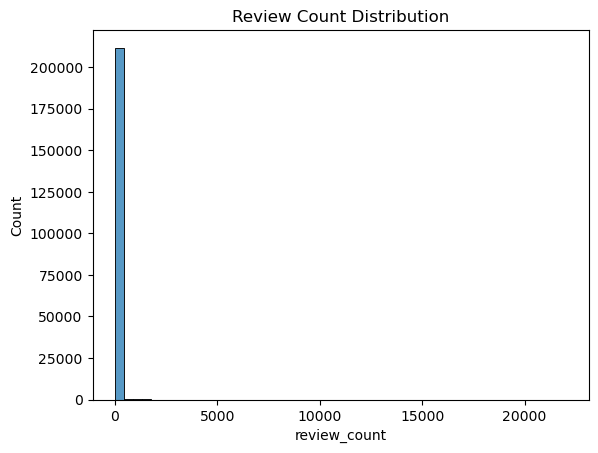

In [11]:
# Review count distribution
sns.histplot(aggr_data['review_count'], bins=50)
plt.title('Review Count Distribution')
plt.show()

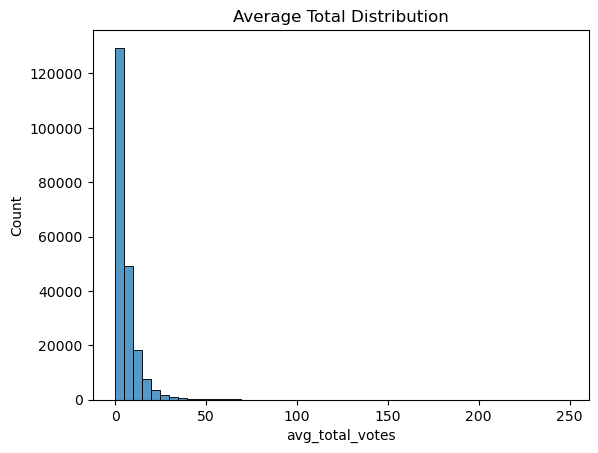

In [ ]:
# Average Total distribution
sns.histplot(aggr_data['avg_total_votes'], bins=50)
plt.title('Average Total Distribution')
plt.show()

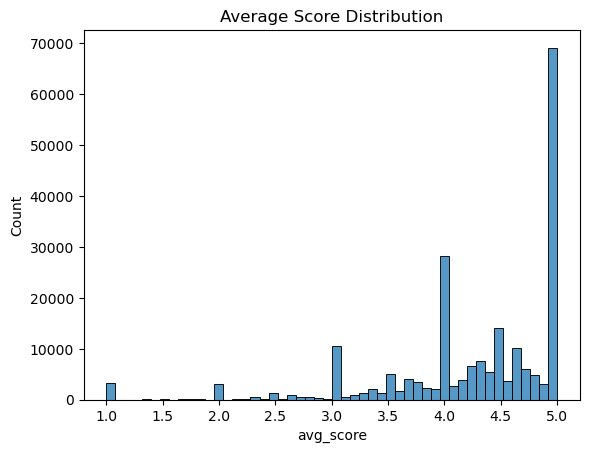

In [14]:
# Average Score distribution
sns.histplot(aggr_data['avg_score'], bins=50)
plt.title('Average Score Distribution')
plt.show()

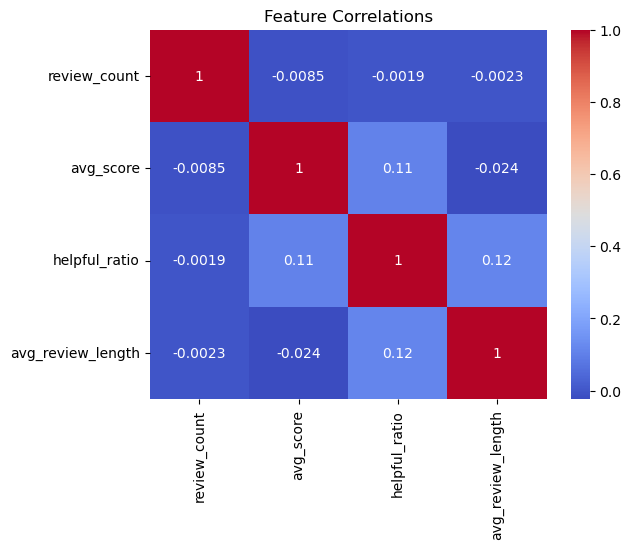

In [15]:
# Correlation
corr = aggr_data[['review_count', 'avg_score', 'helpful_ratio', 'avg_review_length']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Feature Correlations')
plt.show()

In [16]:
# Identify top bestseller
top_books = aggr_data.sort_values('review_count', ascending=False).head(10)
print("Top Bestsellers by Review Count:\n", top_books[['Title', 'review_count']])

Top Bestsellers by Review Count:
                                         Title  review_count
166774                             The Hobbit         22023
123882                    Pride and Prejudice         20371
17627                          Atlas Shrugged         12513
210378                      Wuthering Heights         10780
164672                              The Giver          7644
67539                      Great Expectations          7421
70372   Harry Potter and The Sorcerer's Stone          6796
113065                        Of Mice and Men          6728
26051                         Brave New World          6312
102197                      Mere Christianity          6053


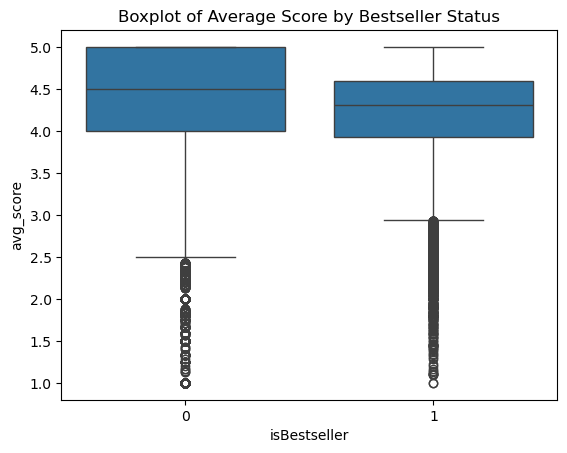

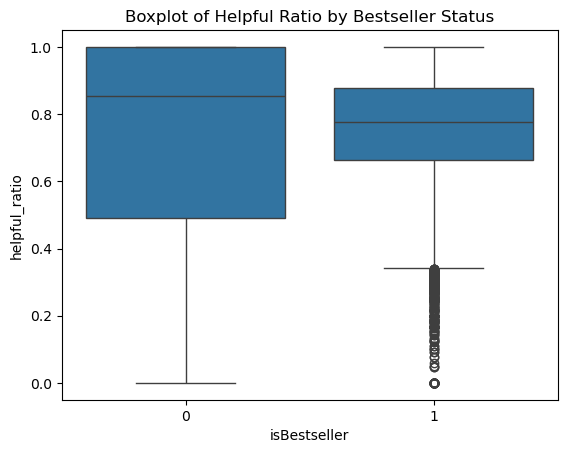

In [50]:
# Boxplot for avg_score by isBestseller
sns.boxplot(x='isBestseller', y='avg_score', data=aggr_data)
plt.title('Boxplot of Average Score by Bestseller Status')
plt.show()

sns.boxplot(x='isBestseller', y='helpful_ratio', data=aggr_data)
plt.title('Boxplot of Helpful Ratio by Bestseller Status')
plt.show()

sns.boxplot(x='isBestseller', y='review_count', data=aggr_data)
plt.title('Boxplot of Review Count by Bestseller Status')
plt.show()


In [35]:
# check frequency distribution of values in review_count variable
aggr_data.review_count.value_counts()

review_count
1       64857
2       33377
3       20323
4       14879
5       10495
        ...  
980         1
874         1
796         1
1012        1
714         1
Name: count, Length: 944, dtype: int64

In [ ]:
# find categorical variables
categorical = [var for var in aggr_data.columns if aggr_data[var].dtype=='O']
print('There are {} categorical variables\n'.format(len(categorical)))
print('The categorical variables are :', categorical)
# (Banerjee, P. 2020)

There are 1 categorical variables

The categorical variables are : ['Title']


In [ ]:
# view the categorical variables
aggr_data[categorical].head()
# (Banerjee, P. 2020)

,Title
0,""" Film technique, "" and, "" Film acting """
1,""" We'll Always Have Paris"": The Definitive Gui..."
2,"""... And Poetry is Born ..."" Russian Classical..."
3,"""A Titanic hero"" Thomas Andrews, shipbuilder"
4,"""A Truthful Impression of the Country"": Britis..."


In [ ]:
# Enhanced correlation heatmap including target
corr_features = aggr_data[['review_count', 'avg_score', 'helpful_ratio', 'avg_review_length', 'isBestseller']]
corr = corr_features.corr()
sns.heatmap(corr, annot=True, cmap='viridis', fmt='.2f', square=True)
plt.title('Correlation Heatmap For Review Count and Target')
plt.show()

## **Data Wrangling**


In [17]:
# Binary target
threshold = aggr_data['review_count'].quantile(0.75)
aggr_data['isBestseller'] = np.where(aggr_data['review_count'] > threshold, 1, 0)

In [18]:
# Features
features = ['avg_score', 'helpful_ratio', 'avg_review_length']
X = aggr_data[features].values
y = aggr_data['isBestseller'].values

In [19]:
# Scale
scaler = StandardScaler()
X = scaler.fit_transform(X)

In [20]:
# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## **Logistic Functions**

In [21]:
# Compute the sigmoid function.
# z: A scalar or numpy array.
# Returns: Sigmoid of z, element-wise if z is an array.
# The sigmoid function maps any real value to (0, 1), useful for probabilities.
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

<b>What it does:</b> 
This is the logistic function, often known as the sigmoid function.  Any real-valued number z is mapped into the interval (0, 1).

<b>Why it's important:</b>
<li>In logistic regression, the sigmoid function converts the linear combination of features and parameters (z = X·theta) into a probability estimate of the positive class.</li>
<li>Mathematical form: σ(z)=1/1+e^−z </li>
<b>​Behavior:</b>
<li>When z is very large positive, sigmoid ≈ 1</li>
<li>When z is very large negative, sigmoid ≈ 0</li>
<li>When z = 0, sigmoid = 0.5</li>
<b>Vectorized:</b>
Using np.exp allows this function to work on scalars, vectors, or matrices element-wise.

In [22]:
# Compute the regularized logistic regression cost.
# X: Feature matrix (m samples x n features).
# y: Target vector (m samples).
# theta: Parameter vector (n features).
# lambda_reg: Regularization strength (default 0, no regularization).
# Returns: Scalar cost value.
# The cost is the average negative log-likelihood plus L2 regularization (excluding bias).
# A small epsilon (1e-5) is added inside the log to avoid log(0).
def compute_cost(X, y, theta, lambda_reg=0):
    m = len(y)  
    h = sigmoid(np.dot(X, theta))  # Predicted probabilities
    # Compute logistic loss with numerical stability term (1e-5)
    cost = (-1/m) * np.sum(y * np.log(h + 1e-5) + (1 - y) * np.log(1 - h + 1e-5))
    # Regularization term (exclude theta[0], the bias)
    reg = (lambda_reg / (2 * m)) * np.sum(theta[1:]**2)
    return cost + reg

<b>What it does:</b>
<p>Computes the regularized logistic regression cost function (loss) for parameters theta on dataset (X, y).</p>
<b>Step-by-step:</b>
<li>m is the number of training data.</li>
<li>h is the predicted probability vector for all data (using the sigmoid function).</li>
<li>The cost is the average negative log-likelihood (also called cross-entropy loss), measuring how well the model predicts the true labels y.</li>
<li>1e-5 is added inside the log to avoid numerical issues like log(0).</li>
<li>reg is the L2 regularization term (ridge penalty), applied to all parameters except the bias term (theta[0]). </li><li>This helps prevent overfitting by penalizing large weights.</li>
<b>Why:</b>
Minimizing this cost function finds parameters theta that best fit the data while controlling complexity.

In [23]:
# Compute the gradient of the regularized logistic regression cost.
# X: Feature matrix (m x n).
# y: Target vector (m,).
# theta: Parameter vector (n,).
# lambda_reg: Regularization strength.
# Returns: Gradient vector (n,).
# Gradient is average error weighted by features plus regularization (excluding bias).
def compute_gradient(X, y, theta, lambda_reg=0):
    m = len(y)
    h = sigmoid(np.dot(X, theta))  # Predicted probabilities
    grad = (1/m) * np.dot(X.T, (h - y))  # Gradient of loss
    reg = (lambda_reg / m) * theta  # Regularization term for gradient
    reg[0] = 0  
    return grad + reg

<b>What it does:</b>
<p>Computes the gradient (partial derivatives) of the cost function with respect to each parameter in theta.</p>
<b>Step-by-step:</b>
<li>h is the predicted probabilities.</li>
<li>grad is the vector of gradients for each parameter, calculated as the average difference between predictions and true labels, weighted by features.</li>
<li>reg adds the gradient of the regularization term for all parameters except the bias (reg[0] = 0 means no regularization on bias).</li>
<b>Why:</b>
The gradient tells us the direction and magnitude to update each parameter to reduce the cost.

In [25]:
# Optimize theta using mini-batch gradient descent.
# X: Feature matrix (m x n).
# y: Target vector (m,).
# theta: Initial parameters (n,).
# alpha: Learning rate.
# num_iters: Number of passes over the dataset.
# lambda_reg: Regularization strength.
# batch_size: Mini-batch size.
# Returns: Tuple of (optimized theta, list of cost values per iteration).
# Each iteration shuffles data, processes mini-batches, updates theta, and records cost on full dataset.
def mini_batch_gradient_descent(X, y, theta, alpha, num_iters, lambda_reg, batch_size=512):
    costs = []
    m = len(y)
    for i in range(num_iters):
        indices = np.random.permutation(m)  # Shuffle indices
        for start in range(0, m, batch_size):
            end = min(start + batch_size, m)
            X_batch = X[indices[start:end]]
            y_batch = y[indices[start:end]]
            grad = compute_gradient(X_batch, y_batch, theta, lambda_reg)
            theta -= alpha * grad  
        cost = compute_cost(X, y, theta, lambda_reg) 
        costs.append(cost)
    return theta, costs

<b>What it does:</b>
<p>Performs mini-batch gradient descent to optimize theta.</p>
<b>Step-by-step:</b>
<p>num_iters is the number of full passes (epochs) over the dataset.</p>
<b>Each iteration:</b>
<li>Shuffle the data indices randomly (np.random.permutation) to avoid bias.</li>
<li>Split data into mini-batches of size batch_size (default 512).</li>
<li>For each mini-batch, compute the gradient and update theta by moving opposite to the gradient scaled by learning rate alpha.</li>
<li>After processing all mini-batches in an iteration, compute and record the cost on the full dataset.</li>
<b>Why mini-batch?</b>
<li>Balances between full batch gradient descent (slow but stable) and stochastic gradient descent (fast but noisy).</li>
<li>Improves convergence speed and stability.</li>

In [ ]:
# Predict binary labels using learned logistic regression parameters.
# X: Feature matrix (m x n).
# theta: Parameter vector (n,).
# threshold: Classification threshold (default 0.5).
# Returns: Boolean numpy array where True means class 1, False means class 0.
def predict(X, theta, threshold=0.5):
    return sigmoid(np.dot(X, theta)) >= threshold

<function sigmoid at 0x00000241EF0AFC40>


<b>What it does:</b>
<p>Predicts binary class labels for input data X using learned parameters theta.</p>
<b>Step-by-step:</b>
<li>Computes predicted probabilities with the sigmoid function.</li>
<li>Compares probabilities to a threshold (default 0.5).</li>
<li>Returns a boolean array: True for predicted positive class, False for negative.</li>
<b>Why:</b>
Converts continuous probability outputs into discrete class predictions.

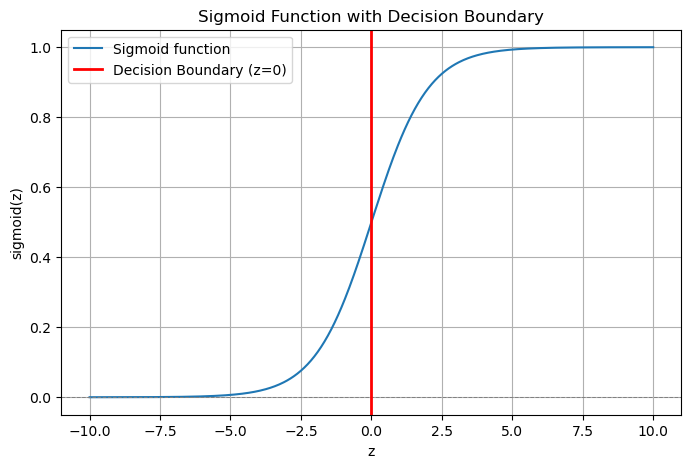

In [ ]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Give a range of values from -10 to 10
x = np.linspace(-10, 10, 500)

# Compute sigmoid values for each x
y = sigmoid(x)

# Plot the sigmoid curve
plt.figure(figsize=(8, 5))
plt.plot(x, y, label='Sigmoid function')

# Add horizontal and vertical reference lines
plt.axhline(0, color='gray', linestyle='--', linewidth=0.7)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.7)

# Add decision boundary line where sigmoid(z) = 0.5 (at z=0)
plt.axvline(0, color='red', linestyle='-', linewidth=2, label='Decision Boundary (z=0)')

plt.title('Sigmoid Function with Decision Boundary')
plt.xlabel('z')
plt.ylabel('sigmoid(z)')
plt.grid(True)
plt.legend()
plt.show()
# (GrokAI, 2025)

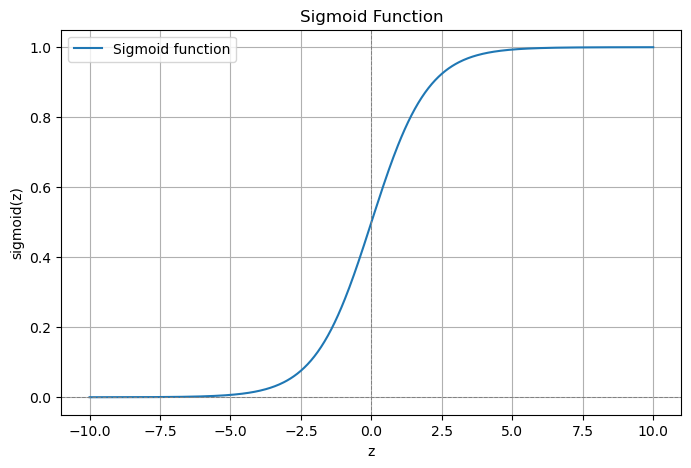

In [ ]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Give a range of values from -10 to 10
x = np.linspace(-10, 10, 500)

# Compute sigmoid values for each x
y = sigmoid(x)

# Plot the sigmoid curve
plt.figure(figsize=(8, 5))
plt.plot(x, y, label='Sigmoid function')
plt.axhline(0, color='gray', linestyle='--', linewidth=0.7)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.7)
plt.title('Sigmoid Function')
plt.xlabel('z')
plt.ylabel('sigmoid(z)')
plt.grid(True)
plt.legend()
plt.show()


## **Model Training and Fit Management**

In [ ]:
# train a logistic regression model on the training set
from sklearn.linear_model import LogisticRegression
# instantiate the model
log_reg = LogisticRegression(solver='liblinear', random_state=42)
# fit the model
log_reg.fit(X_train, y_train)
# (Banerjee, P. 2020)

LogisticRegression(random_state=42, solver='liblinear')

In [ ]:
y_pred_test = log_reg.predict(X_test)

y_pred_test
# (Banerjee, P. 2020)

array([0, 0, 0, ..., 0, 0, 0])

In [ ]:
# probability of getting output as 0 
log_reg.predict_proba(X_test)[:,0]
# (Banerjee, P. 2020)

array([0.76262029, 0.72267488, 0.86891101, ..., 0.78361616, 0.74686377,
       0.74279674])

In [ ]:
# probability of getting output as 1 
log_reg.predict_proba(X_test)[:,1]
# (Banerjee, P. 2020)

array([0.23737971, 0.27732512, 0.13108899, ..., 0.21638384, 0.25313623,
       0.25720326])

In [ ]:
print('Model accuracy score: {0:0.4f}'. format(accuracy_score(y_test, y_pred_test)))
# (Banerjee, P. 2020)

Model accuracy score: 0.7725


In [ ]:
y_pred_train = log_reg.predict(X_train)
y_pred_train
# (Banerjee, P. 2020)

array([0, 0, 0, ..., 0, 0, 0])

In [ ]:
print('Training-set accuracy score: {0:0.4f}'. format(accuracy_score(y_train, y_pred_train)))
# (Banerjee, P. 2020)

Training-set accuracy score: 0.7730


In [ ]:
# print the scores on training and test set
print('Training set score: {:.4f}'.format(log_reg.score(X_train, y_train)))
print('Test set score: {:.4f}'.format(log_reg.score(X_test, y_test)))
# (Banerjee, P. 2020)

Training set score: 0.7730
Test set score: 0.7725


In [ ]:
# fit the Logsitic Regression model with C=5000
# instantiate the model
log_reg5000 = LogisticRegression(C=5000, solver='liblinear', random_state=42)
# fit the model
log_reg5000.fit(X_train, y_train)
# (Banerjee, P. 2020)

LogisticRegression(C=5000, random_state=42, solver='liblinear')

In [91]:
# print the scores on training and test set
print('Training set score: {:.4f}'.format(log_reg5000.score(X_train, y_train)))
print('Test set score: {:.4f}'.format(log_reg5000.score(X_test, y_test)))

Training set score: 0.7730
Test set score: 0.7725


In [ ]:
# check class distribution in test set
# Count occurrences of each unique value
print("Class distribution:")
unique, counts = np.unique(y_test, return_counts=True)
for value, count in zip(unique, counts):
    percentage = count / len(y_test) * 100
    print(f"Class {value}: {count} samples ({percentage:.2f}%)")


Class distribution:
Class 0: 32816 samples (77.25%)
Class 1: 9665 samples (22.75%)


#### This means that in the test dataset, about 77% of the samples belong to Class 0 (the majority class), and about 23% belong to Class 1 (the minority class).

In [ ]:
# create a new matrix for training data
X_train_bias = np.c_[np.ones(X_train.shape[0]), X_train]
X_test_bias = np.c_[np.ones(X_test.shape[0]), X_test]

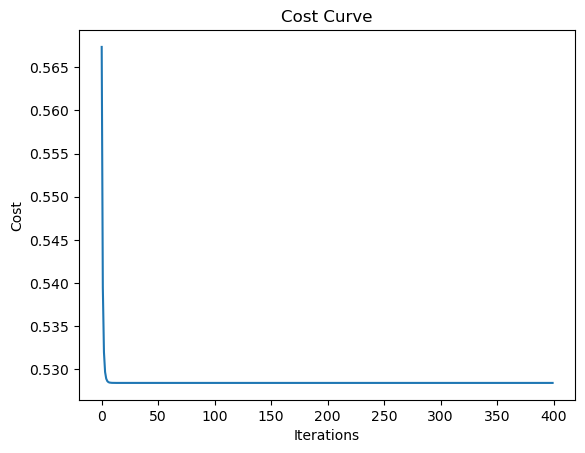

In [28]:
theta = np.zeros(X_train_bias.shape[1])

theta_base, costs_base = mini_batch_gradient_descent(X_train_bias, y_train, theta.copy(), 0.01, 400, 0)

plt.plot(costs_base)
plt.title('Cost Curve')
plt.xlabel('Iterations')
plt.ylabel('Cost')
plt.show()

#### The cost curve shows a typical and healthy training process where the model quickly reduces error and then converges to a stable solution after about 50 iterations, maintaining a low cost for the remaining iterations.

## **Tuning Hyperparameters**

In [ ]:
alphas = [0.001, 0.01, 0.1]
iters = [200, 400, 800]
lambdas = [0.10, 1.0, 10.0]
# (GrokAI, 2025)

In [61]:
# Initialize variables to store the best results
best_theta = None
best_cost = np.inf
best_params = {}

In [31]:
# Loop over all combinations of learning rates, iterations, and regularization parameters
for alpha in alphas:
    for num_iter in iters:
        for lambda_reg in lambdas:
            # Initialize theta to zeros for each run
            theta_temp = np.zeros(X_train_bias.shape[1])
            
            # Run mini-batch gradient descent with current hyperparameters
            theta_temp, _ = mini_batch_gradient_descent(
                X_train_bias, y_train, theta_temp, alpha, num_iter, lambda_reg
            )
            
            # Compute cost on the test set to evaluate performance
            test_cost = compute_cost(X_test_bias, y_test, theta_temp, lambda_reg)
            
            # Update best parameters if current cost is lower
            if test_cost < best_cost:
                best_cost = test_cost
                best_theta = theta_temp
                best_params = {
                    'alpha': alpha,
                    'num_iters': num_iter,
                    'lambda_reg': lambda_reg
                }

# Print the best hyperparameters found
print('Best Parameters:', best_params)
print('Best Cost:', best_cost)

Best Parameters: {'alpha': 0.1, 'num_iters': 400, 'lambda_reg': 0}
Best Cost: 0.5294121935215287


In [41]:
# Predict binary labels on test data using the best learned parameters
y_pred = predict(X_test_bias, best_theta)

# Calculate evaluation metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f'Accuracy: {acc:.4f}, Precision: {prec:.4f}, Recall: {rec:.4f}, F1: {f1:.4f}')

Accuracy: 0.7725, Precision: 0.0000, Recall: 0.0000, F1: 0.0000


c:\Users\User\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


#### The accuracy is 0.7725 (77.25%).
#### This indicates that approximately 77% of the time, the model accurately predicted the class (positive or negative). The percentage of all accurate forecasts among all forecasts is known as accuracy.
#### Precision = 0.0000
#### Precision measures how many of the samples predicted as positive are actually positive. A precision of zero means the model did not predict any positive samples correctly — in fact, it likely predicted no positive samples at all.
#### Recall = 0.0000
#### Recall measures how many of the actual positive samples the model correctly identified. A recall of zero means the model did not identify any of the true positive cases.
#### F1 Score = 0.0000
#### The F1 score is the harmonic mean of precision and recall, balancing both metrics. Since both precision and recall are zero, the F1 score is also zero.

In [59]:
score = accuracy_score(y_test, y_pred)
print(score)

0.7724865233869259


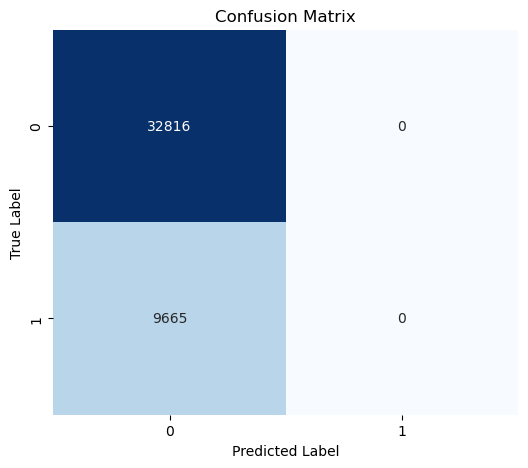

In [ ]:
# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()
# (GrokAI, 2025)


In [ ]:
# Print the Confusion Matrix and slice it into four pieces
# (Banerjee, P. 2020)
cm = confusion_matrix(y_test, y_pred_test)
print('Confusion matrix\n\n', cm)
print('\nTrue Positives(TP) = ', cm[0,0])
print('\nTrue Negatives(TN) = ', cm[1,1])
print('\nFalse Positives(FP) = ', cm[0,1])
print('\nFalse Negatives(FN) = ', cm[1,0])

Confusion matrix

 [[32816     0]
 [ 9665     0]]

True Positives(TP) =  32816

True Negatives(TN) =  0

False Positives(FP) =  0

False Negatives(FN) =  9665


<li><b>True Positives (TP = 32816):</b>
These are the data that actually belong to Class 0 and were correctly predicted as Class 0.</li>
<li><b>True Negatives (TN = 0):</b>
Data that actually belong to Class 1 and were correctly predicted as Class 1. Here, this is zero, meaning the model never predicted Class 1 correctly.</li>
<li><b>False Positives (FP = 0):</b>
Data that actually belong to Class 1 but were incorrectly predicted as Class 0. Zero here means the model never predicted Class 1 when it was actually Class 0.</li>
<li><b>False Negatives (FN = 9665):</b>
Data that actually belong to Class 1 but were incorrectly predicted as Class 0. This means the model failed to identify any Class 1 samples correctly.</li>

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_test))
# (Banerjee, P. 2020)

              precision    recall  f1-score   support

           0       0.77      1.00      0.87     32816
           1       0.00      0.00      0.00      9665

    accuracy                           0.77     42481
   macro avg       0.39      0.50      0.44     42481
weighted avg       0.60      0.77      0.67     42481



c:\Users\User\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\User\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\User\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
# Compute ROC curve and AUC using predicted probabilities
y_scores = sigmoid(np.dot(X_test_bias, best_theta))  # Probabilities for positive class
fpr, tpr, _ = roc_curve(y_test, y_scores)
roc_auc = auc(fpr, tpr)
# (Banerjee, P. 2020)

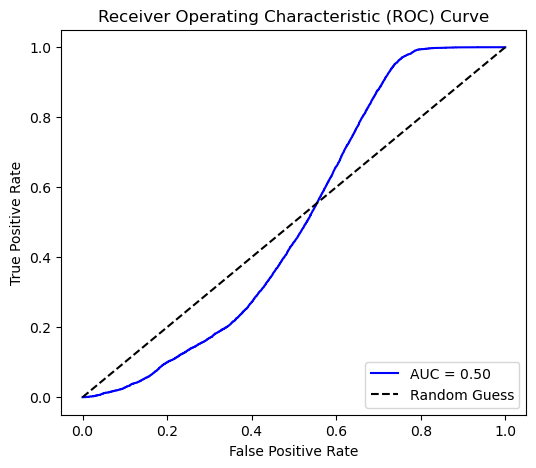

In [44]:
# Plot ROC curve
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}', color='blue')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.show()

<p>Selecting a threshold level that strikes a compromise between sensitivity and specificity for a given situation is made easier by the ROC curve.</p>

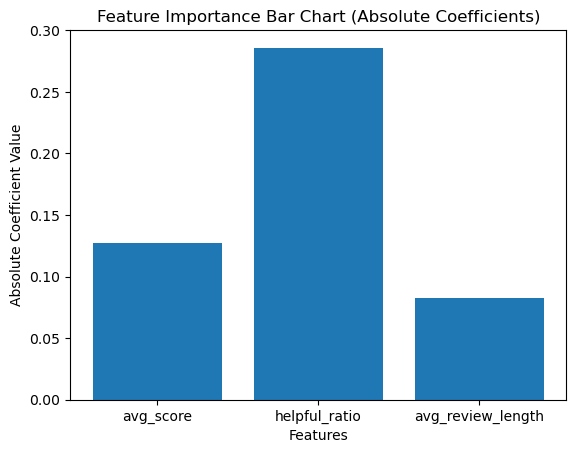

In [ ]:
# Feature importance from coefficients (after fitting best_theta)
features = ['avg_score', 'helpful_ratio', 'avg_review_length']
plt.bar(features, np.abs(importance))
plt.title('Feature Importance Bar Chart (Absolute Coefficients)')
plt.ylabel('Absolute Coefficient Value')
plt.xlabel('Features')
plt.show()
# (GrokAI, 2025)

In [108]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelBinarizer

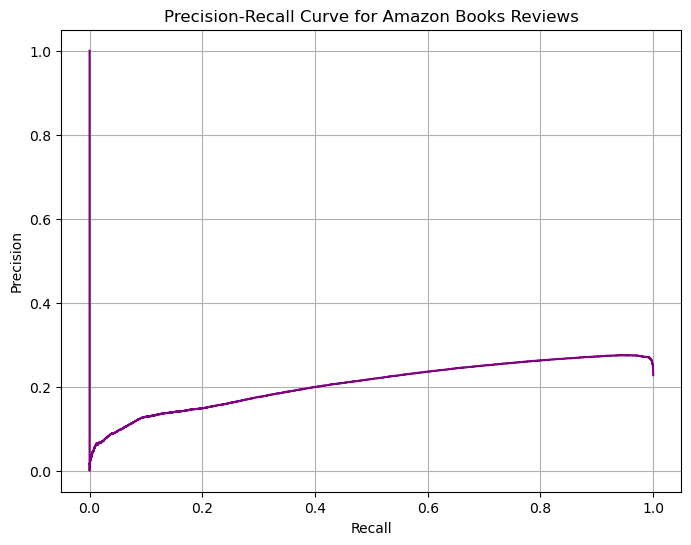

In [110]:
classifier = LogisticRegression(max_iter=100000)
classifier.fit(X_train, y_train)
y_score = classifier.predict_proba(X_test)[:, 1]

# Compute precision, recall, and thresholds
precision, recall, thresholds = precision_recall_curve(y_test, y_score)

# Plot the precision-recall curve
plt.figure(figsize=(8,6))
plt.plot(recall, precision, color='purple')
plt.title('Precision-Recall Curve for Amazon Books Reviews')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.grid(True)
plt.show()

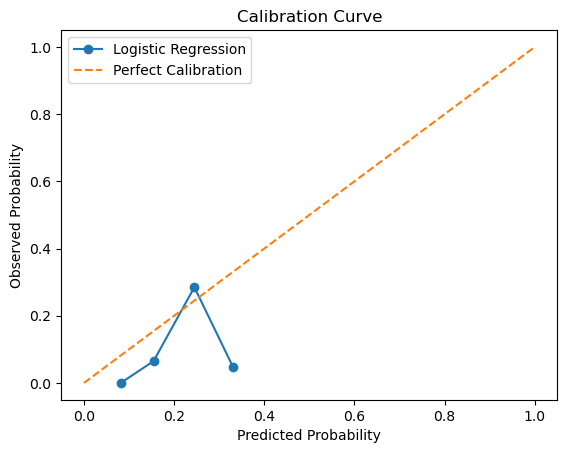

In [ ]:
from sklearn.calibration import calibration_curve

# Calibration curve
prob_true, prob_pred = calibration_curve(y_test, sigmoid(np.dot(X_test_bias, best_theta)), n_bins=10)
plt.plot(prob_pred, prob_true, marker='o', label='Logistic Regression')
plt.plot([0, 1], [0, 1], linestyle='--', label='Ideal Calibration')
plt.title('Calibration Curve for Logistic Regression')
plt.xlabel('Predicted Probability')
plt.ylabel('Observed Probability')
plt.legend()
plt.show()
# (GrokAI, 2025)

In [54]:
!pip install shap

   ---------------------------------------- 0.0/548.0 kB ? eta -:--:--
   ---------------------------------------- 0.0/548.0 kB ? eta -:--:--
   ---------------------------------------- 0.0/548.0 kB ? eta -:--:--
   ---------------------------------------- 548.0/548.0 kB 2.0 MB/s  0:00:00

   ---------------------------------------- 0/2 [slicer]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2

In [58]:
# Define prediction function that adds bias column internally
def model_predict(x):
    x_bias = np.c_[np.ones(x.shape[0]), x]  # add bias column
    return sigmoid(np.dot(x_bias, best_theta))

# Use a subset of training data WITHOUT bias column as background for KernelExplainer
background = X_train  # shape (m, n) without bias column

# Create KernelExplainer with the model prediction function and background data
explainer = shap.KernelExplainer(model_predict, background)

# Compute SHAP values for test data WITHOUT bias column
shap_values = explainer.shap_values(X_test)  # returns list for binary classification

# shap_values[1] corresponds to positive class explanations
shap.summary_plot(shap_values[1], X_test, feature_names=features, plot_type='dot')
plt.title('SHAP Summary Plot for Bestseller Prediction')
plt.show()

Using 169922 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.


  0%|          | 0/42481 [00:00<?, ?it/s]

C:\Users\User\AppData\Local\Temp\ipykernel_3988\3468230909.py:16: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values[1], X_test, feature_names=features, plot_type='dot')


AssertionError: Summary plots need a matrix of shap_values, not a vector.

In [62]:
print(shap_values[1].shape)


(3,)


In [63]:
if len(shap_values[1].shape) == 1:
    shap_values_reshaped = shap_values[1].reshape(1, -1)
else:
    shap_values_reshaped = shap_values[1]


In [ ]:
X_test_subset = X_test[:100]  # first 100 samples
shap_values = explainer.shap_values(X_test_subset)



SHAP values shape: (3,)
X_test shape: (42481, 3)


In [71]:
print(best_theta)  # Check if this prints a numpy array or None


None


## **REFERENCES**


#### Banerjee, P. 2020. Logistic Regression Classifier Tutorial, *Kaggle*. [Online]. Available at: https://www.kaggle.com/code/prashant111/logistic-regression-classifier-tutorial#18.-ROC---AUC- [Accessed on 28 October 2025].
#### Breiman, L. 2001. Random forests, *Machine Learning*, 45(1), pp. 5-32.
#### Cox, D.R. 1958. The regression analysis of binary sequences, *Journal of the Royal Statistical Society: Series B*, 20(2), pp. 215-232.
#### Data Science. 2025. Trying to understand Logistic Regression Implementation, *Stack Exchange*. [Online]. Available at: https://datascience.stackexchange.com/questions/8657/trying-to-understand-logistic-regression-implementation [Accessed on 28 October 2025].
#### GrokAI. 2025. [Online]. Available at: https://grok.com/ [Accessed 28 October 2025].
#### Hastie, T., Tibshirani, R. and Friedman, J. (2009) The elements of statistical learning. 2nd edn. New York: Springer.
#### Hosmer, D.W., Lemeshow, S. and Sturdivant, R.X. (2013) Applied logistic regression. 3rd edn. Hoboken: Wiley.
##### IIE Emeris School of Computer Science. 2025. PDAN8412w Tutorials 20251023 Logistic Regression POE Part 2, *YouTube*. [Online]. Available at: https://www.youtube.com/watch?v=lgWB69nWuF0&list=PL480DYS-b_kd6IuBak8le1pvHeZql-Isy&index=3 [Accessed 29 October 2025].
#### James, G. et al. 2013. An introduction to statistical learning. New York: Springer.
#### Kleinbaum, D.G. and Klein, M. 2010. Logistic regression. 3rd edn. New York: Springer.
#### Mohamedbakhet. 2023. Amazon Books Reviews, *Kaggle*. [Online]. Available at: https://www.kaggle.com/datasets/mohamedbakhet/amazon-books-reviews [Accessed: 30 October 2025].
#### Ricci, F. et al. 2011. Recommender systems handbook. New York: Springer.
#### Theobald, O. 2017. Machine learning for absolute beginners. 2nd edn. Scatterplot Press.


